# Préparation du dataset WAF
Objectif : transformer le CSV brut en `train.parquet` et `test.parquet` utilisables par les modèles.

In [1]:
import sys, os
sys.path.append("..")
os.makedirs("../rapport", exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from preprocessing import build_text_df, REQ_COLS

pd.set_option("display.max_colwidth", 120)

## 1. Chargement
On lit tout en texte (`dtype=str`) pour éviter les types mélangés et les faux doublons (`"1"` contre `1`).

In [2]:
df = pd.read_csv("../data/data_capec_multilabel.csv", dtype=str)
print(df.shape)
print(df.columns.tolist())

(907815, 38)
['timestamp', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'request_http_method', 'request_http_request', 'request_http_protocol', 'request_user_agent', 'request_referer', 'request_host', 'request_origin', 'request_cookie', 'request_content_type', 'request_accept', 'request_accept_language', 'request_accept_encoding', 'request_do_not_track', 'request_connection', 'request_body', 'response_http_protocol', 'response_http_status_code', 'response_http_status_message', 'response_content_length', '000 - Normal', '272 - Protocol Manipulation', '242 - Code Injection', '88 - OS Command Injection', '126 - Path Traversal', '66 - SQL Injection', '16 - Dictionary-based Password Attack', '310 - Scanning for Vulnerable Software', '153 - Input Data Manipulation', '248 - Command Injection', '274 - HTTP Verb Tampering', '194 - Fake the Source of Data', '34 - HTTP Response Splitting', '33 - HTTP Request Smuggling']


## 2. Exploration
Constats principaux : 907 815 requêtes, 58 % légitimes / 42 % malveillantes, SQL Injection dominant, `248 - Command Injection` quasi absent (1 requête), 9 238 requêtes multi-label, colonnes vides à 100 % (`request_do_not_track`, `request_origin`), et une fuite par le code de réponse (règle « 200 = légitime » donnant ~82 % d'accuracy).

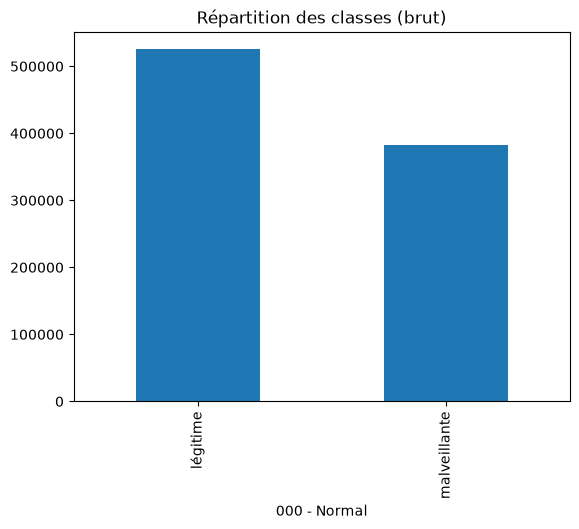

In [3]:
# Graphique 1 : équilibre des classes
df["000 - Normal"].map({"1": "légitime", "0": "malveillante"}).value_counts().plot.bar(title="Répartition des classes (brut)")
plt.savefig("../rapport/fig_classes.png", bbox_inches="tight")
plt.show()

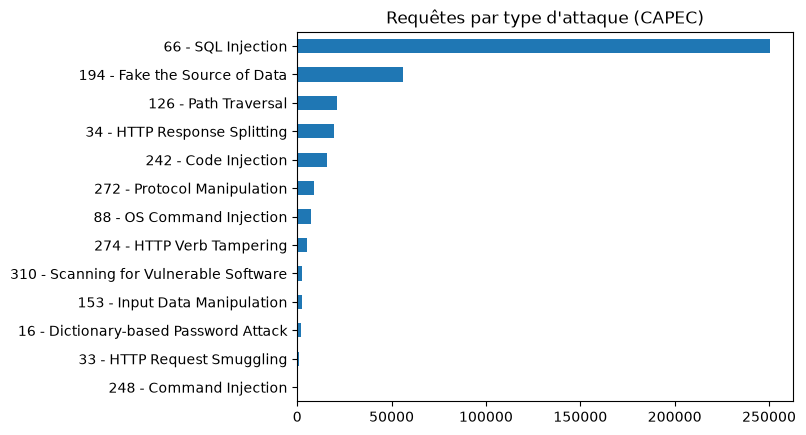

In [4]:
# Graphique 2 : types d'attaque
label_cols = df.columns[24:].tolist()
attack_cols = label_cols[1:]
df[attack_cols].astype(int).sum().sort_values().plot.barh(title="Requêtes par type d'attaque (CAPEC)")
plt.savefig("../rapport/fig_attaques.png", bbox_inches="tight")
plt.show()

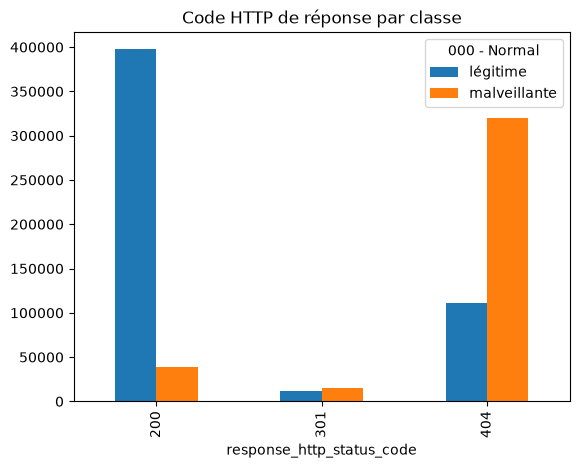

In [5]:
# Graphique 3 : la fuite par le code de réponse
ct = pd.crosstab(df["response_http_status_code"], df["000 - Normal"].map({"1": "légitime", "0": "malveillante"}))
ct.loc[["200", "301", "404"]].plot.bar(title="Code HTTP de réponse par classe")
plt.savefig("../rapport/fig_codes_http.png", bbox_inches="tight")
plt.show()

## 3. Labels
`label = 1 - "000 - Normal"` : 1 = malveillante (ce qu'on cherche à détecter), 0 = légitime. On garde les 13 colonnes CAPEC pour le bonus de type d'attaque.

In [6]:
label_cols  = df.columns[24:].tolist()   # 000 - Normal + 13 CAPEC
attack_cols = label_cols[1:]               # les 13 CAPEC

df[label_cols] = df[label_cols].astype(int)
df["label"] = 1 - df["000 - Normal"]

## 4. Suppression des colonnes
- Identifiants (timestamp, IP, ports) : le modèle apprendrait des adresses ou des heures, pas des attaques.
- `response_*` : un WAF décide avant la réponse du serveur, cette information n'existe pas en production.
- Colonnes vides à 100 % : aucune information.

In [7]:
drop_cols = (
    ["timestamp", "src_ip", "src_port", "dst_ip", "dst_port"]
    + [c for c in df.columns if c.startswith("response_")]
    + ["request_do_not_track", "request_origin"]
    + ["000 - Normal"]
)
df = df.drop(columns=drop_cols)
df.columns.tolist()

['request_http_method',
 'request_http_request',
 'request_http_protocol',
 'request_user_agent',
 'request_referer',
 'request_host',
 'request_cookie',
 'request_content_type',
 'request_accept',
 'request_accept_language',
 'request_accept_encoding',
 'request_connection',
 'request_body',
 '272 - Protocol Manipulation',
 '242 - Code Injection',
 '88 - OS Command Injection',
 '126 - Path Traversal',
 '66 - SQL Injection',
 '16 - Dictionary-based Password Attack',
 '310 - Scanning for Vulnerable Software',
 '153 - Input Data Manipulation',
 '248 - Command Injection',
 '274 - HTTP Verb Tampering',
 '194 - Fake the Source of Data',
 '34 - HTTP Response Splitting',
 '33 - HTTP Request Smuggling',
 'label']

## 5. Construction du texte
`build_text_df` normalise Host et Referer (sinon le modèle apprend `test-site.com` et bloquerait tout en démo sur `localhost`), décode l'URL deux fois, met en minuscules et concatène les champs `request_*`.

In [8]:
df["text"] = build_text_df(df)
for lab in (0, 1):
    print(f"--- label {lab} ---")
    for t in df[df["label"] == lab]["text"].sample(3, random_state=42):
        print(t[:200])
        print()

--- label 0 ---
request_http_method get request_http_request /blog/index.php/my-account/edit-profile/{{ data.sizes.large.url }} request_http_protocol http/1.1 request_user_agent mozilla/5.0 (x11; linux x86_64; rv:70.

request_http_method get request_http_request /blog/wp-login.php request_http_protocol http/1.1 request_user_agent mozilla/5.0 (windows nt 10.0; wow64; trident/7.0; rv:11.0) like gecko request_referer 

request_http_method get request_http_request / request_http_protocol http/1.1 request_user_agent mozilla/5.0 (windows nt 10.0; wow64; rv:37.0) gecko/20100101 firefox/37.0 request_referer  request_host

--- label 1 ---
request_http_method get request_http_request /blog'+and+'1'='1/wp-includes/js/media-audiovideo.min.js?ver=4.9.5 request_http_protocol http/1.1 request_user_agent mozilla/5.0 (x11; linux x86_64; rv:70.

request_http_method get request_http_request /blog/wp-content/uploads/2020/04/27f17687-adda-3ce6-9767-0037ea74eec2.png||sleep+15 request_http_protocol http/1.1 

## 6. Dédoublonnage et conflits
On dédoublonne après `build_text` (le décodage peut rendre identiques des requêtes différentes). Les textes contradictoires (labels 0 et 1) sont retirés dans leurs deux versions, car on ne sait pas laquelle est juste. Sans cela, la même requête se retrouverait en train et en test et les scores seraient gonflés.

In [9]:
n_avant = len(df)

conflits = df.groupby("text")["label"].nunique()
textes_conflit = conflits[conflits > 1].index
print(len(textes_conflit), "textes contradictoires")
df = df[~df["text"].isin(textes_conflit)]

df = df.drop_duplicates(subset=["text", "label"])

print(f"{n_avant} -> {len(df)} requêtes")
df["label"].value_counts(normalize=True).round(3)

284 textes contradictoires
907815 -> 534444 requêtes


label
1    0.681
0    0.319
Name: proportion, dtype: float64

In [10]:
print(df.shape)
print(df["label"].value_counts())
print(df["text"].str.len().describe())
assert df["text"].isna().sum() == 0
assert "label" in df.columns and "text" in df.columns

(534444, 28)
label
1    364070
0    170374
Name: count, dtype: int64
count    534444.000000
mean        692.009683
std         178.022901
min         254.000000
25%         537.000000
50%         696.000000
75%         831.000000
max        1344.000000
Name: text, dtype: float64


## 7. Split et sauvegarde
Le split est fait une seule fois, ici, pour que tout le monde évalue sur le même test. `stratify` conserve la même proportion de classes dans train et test. Le test n'est plus utilisé avant l'évaluation finale.

In [11]:
keep = ["text", "label"] + attack_cols

train, test = train_test_split(
    df[keep], test_size=0.2, stratify=df["label"], random_state=42
)
print(len(train), len(test))
print(train["label"].mean().round(3), test["label"].mean().round(3))

train.to_parquet("../data/train.parquet", index=False)
test.to_parquet("../data/test.parquet", index=False)

sample = train.sample(50_000, random_state=42)
sample.to_parquet("../data/sample.parquet", index=False)

427555 106889
0.681 0.681


## 8. Conclusion
- Dataset d'origine : 907 815 requêtes, 38 colonnes.
- Transformations : labels binaires, suppression des identifiants, des colonnes `response_*` et des colonnes vides, normalisation Host/Referer, décodage URL, dédoublonnage.
- Pièges identifiés : fuite par le code de réponse, doublons, biais Host/Referer.
- Limites : un seul site (WordPress), données de 2020, labels en partie issus de ModSecurity, Referer probablement biaisé.